# Phase 1: Exploratory Data Analysis

## 1. Libraries and data loading


In [69]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


### Convert XPT to CSV


In [ ]:
from pathlib import Path

xpt_file = Path('LLCP2023.XPT')
csv_file = Path('LLCP2023.csv')
if not csv_file.exists():
    partial_csv = csv_file.with_suffix('.csv.partial')
    with pd.read_sas(xpt_file, format='xport', iterator=True, chunksize=10000, encoding='utf-8') as reader:
        with partial_csv.open('w', encoding='utf-8', newline='') as output:
            for chunk_number, chunk in enumerate(reader):
                chunk.to_csv(output, index=False, header=(chunk_number == 0))
    partial_csv.replace(csv_file)
print('Using CSV:', csv_file)


### Load CSV


In [ ]:
df = pd.read_csv(csv_file)


In [71]:
df.head()


,_STATE,FMONTH,IDATE,IMONTH,IDAY,IYEAR,DISPCODE,SEQNO,_PSU,CTELENM1,...,DROCDY4_,_RFBING6,_DRNKWK2,_RFDRHV8,_FLSHOT7,_PNEUMO3,_AIDTST4,_RFSEAT2,_RFSEAT3,_DRNKDRV
0,1.0,1.0,3012023,3,1,2023,1100.0,2023000001,2.023000e+09,1.0,...,5.397605e-79,1.0,5.397605e-79,1.0,2.0,2.0,2.0,1.0,1.0,9.0
1,1.0,1.0,1062023,1,6,2023,1100.0,2023000002,2.023000e+09,1.0,...,5.397605e-79,1.0,5.397605e-79,1.0,1.0,1.0,2.0,1.0,1.0,9.0
2,1.0,1.0,3082023,3,8,2023,1100.0,2023000003,2.023000e+09,1.0,...,5.397605e-79,1.0,5.397605e-79,1.0,1.0,1.0,2.0,1.0,1.0,9.0
3,1.0,1.0,3062023,3,6,2023,1100.0,2023000004,2.023000e+09,1.0,...,5.397605e-79,1.0,5.397605e-79,1.0,1.0,1.0,1.0,1.0,1.0,9.0
4,1.0,1.0,1062023,1,6,2023,1100.0,2023000005,2.023000e+09,1.0,...,7.000000e+00,1.0,4.700000e+01,1.0,2.0,1.0,2.0,1.0,1.0,2.0


In [72]:
df.tail()


,_STATE,FMONTH,IDATE,IMONTH,IDAY,IYEAR,DISPCODE,SEQNO,_PSU,CTELENM1,...,DROCDY4_,_RFBING6,_DRNKWK2,_RFDRHV8,_FLSHOT7,_PNEUMO3,_AIDTST4,_RFSEAT2,_RFSEAT3,_DRNKDRV
433318,78.0,12.0,12112023,12,11,2023,1100.0,2023002064,2.023002e+09,NaN,...,7.100000e+01,2.0,1.500000e+03,2.0,2.0,2.0,1.0,1.0,2.0,2.0
433319,78.0,12.0,1032024,1,3,2024,1100.0,2023002065,2.023002e+09,NaN,...,5.397605e-79,1.0,5.397605e-79,1.0,NaN,NaN,1.0,1.0,1.0,9.0
433320,78.0,12.0,12132023,12,13,2023,1100.0,2023002066,2.023002e+09,NaN,...,3.000000e+00,1.0,4.700000e+01,1.0,NaN,NaN,1.0,1.0,1.0,2.0
433321,78.0,12.0,12082023,12,8,2023,1100.0,2023002067,2.023002e+09,NaN,...,5.397605e-79,1.0,5.397605e-79,1.0,2.0,2.0,2.0,1.0,1.0,9.0
433322,78.0,12.0,12112023,12,11,2023,1100.0,2023002068,2.023002e+09,NaN,...,6.700000e+01,2.0,9.330000e+02,1.0,NaN,NaN,2.0,1.0,2.0,2.0


In [73]:
df.shape


(433323, 350)

In [74]:
df.isna().sum()


_STATE           0
FMONTH           0
IDATE            0
IMONTH           0
IDAY             0
             ...  
_PNEUMO3    262500
_AIDTST4     29613
_RFSEAT2         0
_RFSEAT3         0
_DRNKDRV         0
Length: 350, dtype: int64

In [75]:
d = df.columns
d.tolist()


['_STATE',
 'FMONTH',
 'IDATE',
 'IMONTH',
 'IDAY',
 'IYEAR',
 'DISPCODE',
 'SEQNO',
 '_PSU',
 'CTELENM1',
 'PVTRESD1',
 'COLGHOUS',
 'STATERE1',
 'CELPHON1',
 'LADULT1',
 'NUMADULT',
 'RESPSLC1',
 'LANDSEX2',
 'LNDSXBRT',
 'SAFETIME',
 'CTELNUM1',
 'CELLFON5',
 'CADULT1',
 'CELLSEX2',
 'CELSXBRT',
 'PVTRESD3',
 'CCLGHOUS',
 'CSTATE1',
 'LANDLINE',
 'HHADULT',
 'SEXVAR',
 'GENHLTH',
 'PHYSHLTH',
 'MENTHLTH',
 'POORHLTH',
 'PRIMINS1',
 'PERSDOC3',
 'MEDCOST1',
 'CHECKUP1',
 'EXERANY2',
 'EXRACT12',
 'EXEROFT1',
 'EXERHMM1',
 'EXRACT22',
 'EXEROFT2',
 'EXERHMM2',
 'STRENGTH',
 'BPHIGH6',
 'BPMEDS1',
 'CHOLCHK3',
 'TOLDHI3',
 'CHOLMED3',
 'CVDINFR4',
 'CVDCRHD4',
 'CVDSTRK3',
 'ASTHMA3',
 'ASTHNOW',
 'CHCSCNC1',
 'CHCOCNC1',
 'CHCCOPD3',
 'ADDEPEV3',
 'CHCKDNY2',
 'HAVARTH4',
 'DIABETE4',
 'DIABAGE4',
 'MARITAL',
 'EDUCA',
 'RENTHOM1',
 'NUMHHOL4',
 'NUMPHON4',
 'CPDEMO1C',
 'VETERAN3',
 'EMPLOY1',
 'CHILDREN',
 'INCOME3',
 'PREGNANT',
 'WEIGHT2',
 'HEIGHT3',
 'DEAF',
 'BLIND',
 'DECIDE',

In [76]:
df['_STATE'].value_counts()


_STATE
53.0    26444
36.0    17349
24.0    17255
27.0    16170
39.0    13384
12.0    13255
31.0    12886
55.0    12819
23.0    12255
4.0     12036
6.0     11976
49.0    11154
18.0    10993
48.0    10059
45.0    10038
26.0     9978
20.0     9884
25.0     9528
9.0      9501
34.0     9328
19.0     8876
8.0      8783
13.0     8227
15.0     7832
50.0     7636
29.0     7219
30.0     7143
51.0     6981
33.0     6960
16.0     6895
40.0     6727
41.0     6234
46.0     5886
44.0     5781
38.0     5745
47.0     5645
2.0      5525
22.0     5388
5.0      5351
17.0     5279
72.0     4594
56.0     4484
1.0      4362
54.0     4339
10.0     4282
37.0     4088
28.0     4069
35.0     3220
11.0     3207
32.0     2650
78.0     2064
66.0     1559
Name: count, dtype: int64

## 2. State distribution


In [77]:
df['State_per'] = df['_STATE'].apply(lambda x: 1 if x == 47 else 0)


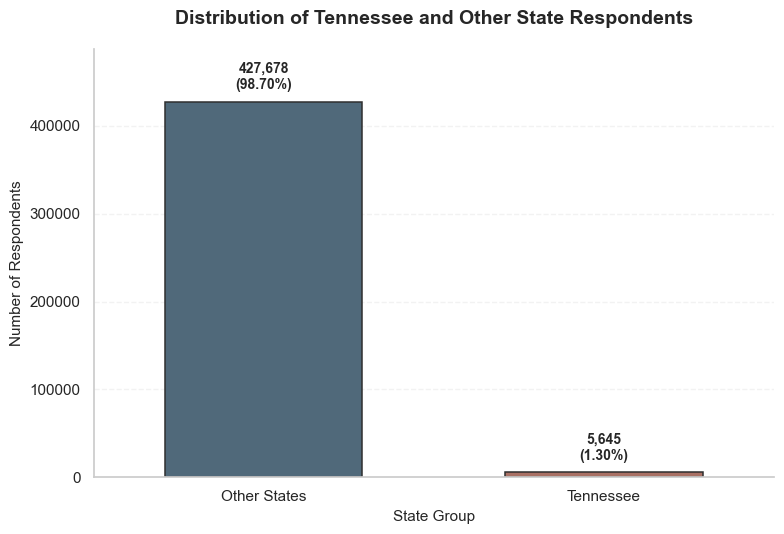

In [78]:
sns.set_theme(style="whitegrid", context="notebook")
custom_palette = ["#496A81", "#B56A5A"]
plt.figure(figsize=(8, 5.5))
ax = sns.countplot(data=df,x='State_per',hue='State_per',palette=custom_palette, width=0.58,edgecolor="#2F2F2F", linewidth=1.1,legend=False)
ax.set_xticks([0, 1])
ax.set_xticklabels( ['Other States', 'Tennessee'], fontsize=11, fontweight='medium')
ax.set_xlabel('State Group', fontsize=11)
ax.set_ylabel('Number of Respondents', fontsize=11)
ax.set_title('Distribution of Tennessee and Other State Respondents',fontsize=14,fontweight='bold',pad=18)
total = len(df)
for bar in ax.patches:
    count = int(bar.get_height())
    percentage = (count / total) * 100
    ax.annotate( f'{count:,}\n({percentage:.2f}%)', xy=( bar.get_x() + bar.get_width() / 2,
            bar.get_height() ), xytext=(0, 7), textcoords='offset points', ha='center', va='bottom', fontsize=10, fontweight='semibold' )
# Give enough space above the tallest bar
max_count = df['State_per'].value_counts().max()
ax.set_ylim(0, max_count * 1.14)
# Cleaner appearance
ax.grid(axis='y', linestyle='--', alpha=0.25)
ax.grid(axis='x', visible=False)
sns.despine(left=False, bottom=False)
plt.tight_layout()
plt.show()


## 3. Tennessee records and source features


In [ ]:
features = [ "_RFHLTH",      # 1. General health
    "_PHYS14D",     # 2. Poor physical-health days
    "_MENT14D",     # 3. Poor mental-health days
    "_HLTHPL1",     # 4. Health insurance
    "_TOTINDA",     # 5. Physical activity
    "_RFHYPE6",     # 6. High blood pressure
    "_RFCHOL3",     # 7. High cholesterol
    "_MICHD",       # 8. CHD / myocardial infarction
    "_CASTHM1",     # 9. Current asthma
    "_DRDXAR2",     # 10. Arthritis
    "_RACEGR3",     # 11. Race / ethnicity
    "_SEX",         # 12. Sex
    "_AGE_G",       # 13. Six-level age group
    "_BMI5CAT",     # 14. BMI category
    "_EDUCAG",      # 15. Education level
    "_INCOMG1",     # 16. Income category
    "_SMOKER3",     # 17. Smoking status
    "DRNKANY6",     # 18. Alcohol use
    "CVDSTRK3",     # 19. Stroke
    "CHCOCNC1",     # 20. Cancer
    "CHCCOPD3",     # 21. COPD
    "ADDEPEV3",     # 22. Depressive disorder
    "CHCKDNY2",     # 23. Kidney disease
    "DIABETE4",     # 24. Diabetes outcome
    "MARITAL",     # 25. Marital status
    "VETERAN3",     # 26. Veteran
    "EMPLOY1",      # 27. Employment
    "PREGNANT",     # 28. Pregnancy
    "DEAF",         # 29. Hearing disability
    "BLIND",        # 30. Vision disability
    "DECIDE",       # 31. Cognitive disability
    "DIFFWALK",     # 32. Walking disability
    "DIFFDRES",     # 33. Dressing disability
    "DIFFALON",     # 34. Errands disability
    "_URBSTAT",     # 35. Urban / rural
    "CIMEMLO1"      # 36. Cognitive decline
]


In [ ]:
print("Number of S1 variables:", len(features))


In [80]:
missing_s1 = [col for col in features if col not in df.columns]
if missing_s1:
    print("Missing columns:")
    print(missing_s1)
else:
    print("All 36 Supplementary Table S1 variables are available.")


All 36 Supplementary Table S1 variables are available.


In [81]:
s1_data = df[df["_STATE"] == 47].copy()
print("Tennessee rows:", s1_data.shape[0])
print("Tennessee columns:", s1_data.shape[1])


Tennessee rows: 5645
Tennessee columns: 351


In [ ]:
s1_data.head()


,_STATE,FMONTH,IDATE,IMONTH,IDAY,IYEAR,DISPCODE,SEQNO,_PSU,CTELENM1,...,_RFBING6,_DRNKWK2,_RFDRHV8,_FLSHOT7,_PNEUMO3,_AIDTST4,_RFSEAT2,_RFSEAT3,_DRNKDRV,State_per
335545,47.0,1.0,2082023,2,8,2023,1100.0,2023000326,2.023000e+09,1.0,...,1.0,9.300000e+01,1.0,NaN,NaN,2.0,1.0,1.0,2.0,1
335546,47.0,1.0,2192023,2,19,2023,1100.0,2023000327,2.023000e+09,1.0,...,1.0,5.397605e-79,1.0,2.0,1.0,1.0,2.0,2.0,9.0,1
335547,47.0,1.0,2162023,2,16,2023,1100.0,2023000328,2.023000e+09,1.0,...,1.0,5.397605e-79,1.0,1.0,1.0,2.0,1.0,1.0,9.0,1
335548,47.0,1.0,2072023,2,7,2023,1100.0,2023000329,2.023000e+09,1.0,...,1.0,5.397605e-79,1.0,1.0,1.0,2.0,1.0,1.0,9.0,1
335549,47.0,1.0,2232023,2,23,2023,1100.0,2023000330,2.023000e+09,1.0,...,1.0,5.397605e-79,1.0,2.0,2.0,9.0,1.0,2.0,9.0,1


In [ ]:
s1_data.tail()


,_STATE,FMONTH,IDATE,IMONTH,IDAY,IYEAR,DISPCODE,SEQNO,_PSU,CTELENM1,...,_RFBING6,_DRNKWK2,_RFDRHV8,_FLSHOT7,_PNEUMO3,_AIDTST4,_RFSEAT2,_RFSEAT3,_DRNKDRV,State_per
341185,47.0,5.0,8202023,8,20,2023,1200.0,2023005641,2.023006e+09,NaN,...,1.0,5.397605e-79,1.0,NaN,NaN,1.0,1.0,2.0,9.0,1
341186,47.0,2.0,4042023,4,4,2023,1200.0,2023005642,2.023006e+09,NaN,...,1.0,2.300000e+01,1.0,NaN,NaN,1.0,1.0,2.0,2.0,1
341187,47.0,6.0,7302023,7,30,2023,1200.0,2023005643,2.023006e+09,NaN,...,1.0,3.000000e+02,1.0,NaN,NaN,2.0,1.0,1.0,2.0,1
341188,47.0,8.0,9082023,9,8,2023,1200.0,2023005644,2.023006e+09,NaN,...,1.0,2.300000e+01,1.0,NaN,NaN,1.0,1.0,1.0,2.0,1
341189,47.0,10.0,11092023,11,9,2023,1200.0,2023005645,2.023006e+09,NaN,...,9.0,9.990000e+04,9.0,NaN,NaN,NaN,9.0,9.0,9.0,1


In [ ]:
s1_data.shape


(5645, 351)

## 4. Original diabetes target


In [ ]:
s1_data['DIABETE4'].value_counts()


DIABETE4
3.0    4476
1.0     957
4.0     131
2.0      70
7.0       6
9.0       5
Name: count, dtype: int64

C:\Users\chali\AppData\Local\Temp\ipykernel_7572\1052087695.py:29: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(


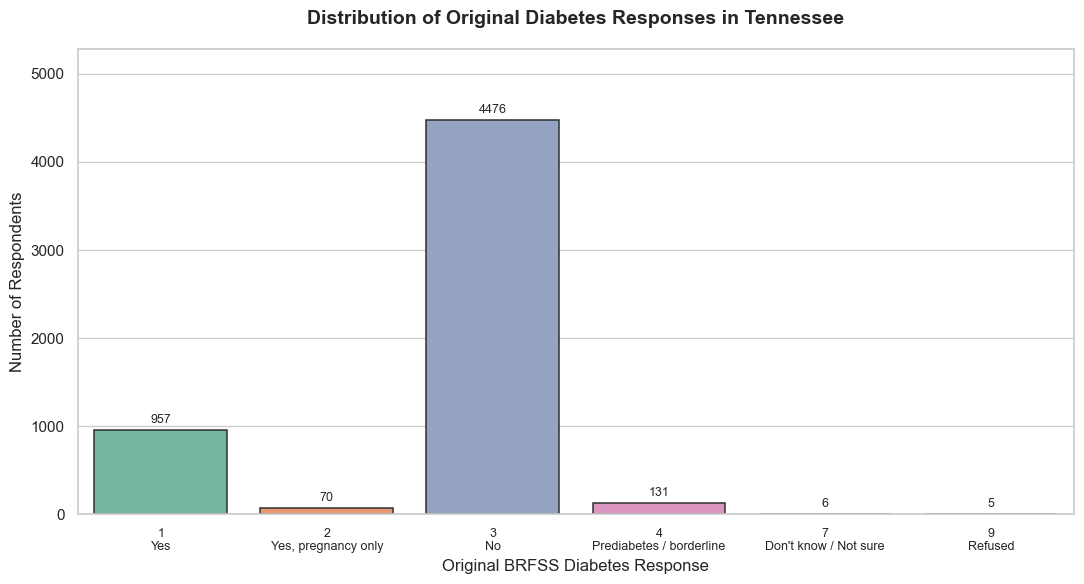

In [ ]:
diabetes_labels = {
    1: "1\nYes", 2: "2\nYes, pregnancy only", 3: "3\nNo", 4: "4\nPrediabetes / borderline", 7: "7\nDon't know / Not sure", 9: "9\nRefused" }
# Keep the original BRFSS order
order = [1.0, 2.0, 3.0, 4.0, 7.0, 9.0]
plt.figure(figsize=(11, 6))
ax = sns.countplot( data=s1_data,
    x="DIABETE4", order=order, hue="DIABETE4", hue_order=order, dodge=False, legend=False, palette="Set2", edgecolor="#2F2F2F", linewidth=1.1 )
# Replace numeric codes with meaningful labels
ax.set_xticklabels( [diabetes_labels[x] for x in order], fontsize=9 )
for container in ax.containers:
    ax.bar_label(container, fmt="%d", padding=3, fontsize=9)
ax.margins(y=0.18)
plt.xlabel("Original BRFSS Diabetes Response")
plt.ylabel("Number of Respondents")
plt.title( "Distribution of Original Diabetes Responses in Tennessee", fontsize=14, fontweight="bold", pad=18 )
plt.tight_layout()
plt.show()


### 4.1 Diabetes target mapping


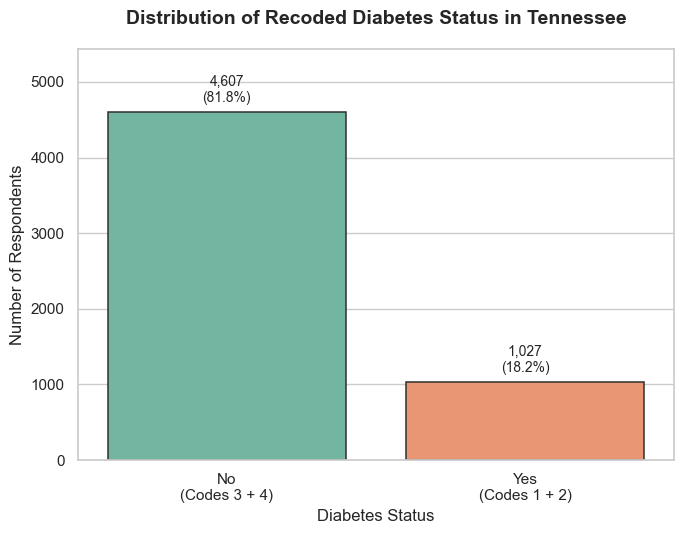

In [ ]:
# Recode responses using the groups shown on the plot.
# Unknown and refused responses remain missing.
s1_data["diabetes"] = s1_data["DIABETE4"].map({1: 1, 2: 1, 3: 0, 4: 0})
# Counts and percentages
counts = s1_data["diabetes"].value_counts().reindex([0, 1], fill_value=0)
percentages = counts / max(counts.sum(), 1) * 100
plt.figure(figsize=(7, 5.5))
ax = sns.countplot( data=s1_data, x="diabetes",
    order=[0.0, 1.0], hue="diabetes", hue_order=[0.0, 1.0], dodge=False, palette="Set2", edgecolor="#2F2F2F", linewidth=1.1, legend=False )
ax.set_xticks([0, 1])
ax.set_xticklabels([ "No\n(Codes 3 + 4)", "Yes\n(Codes 1 + 2)" ])
# Add count and percentage above bars
for container in ax.containers:
    labels = [ f"{int(bar.get_height()):,}\n({bar.get_height() / max(counts.sum(), 1) * 100:.1f}%)" for bar in container ]
    ax.bar_label(container, labels=labels, padding=5, fontsize=10)
ax.margins(y=0.18)
plt.xlabel("Diabetes Status")
plt.ylabel("Number of Respondents")
plt.title( "Distribution of Recoded Diabetes Status in Tennessee", fontsize=14, fontweight="bold", pad=18 )
plt.tight_layout()
plt.show()


## 5. Feature preparation

### 5.1 Demographic features


In [ ]:
features = pd.DataFrame(index=s1_data.index)
# Sex
features["sex"] = s1_data["_SEX"].map({ 1: "Male", 2: "Female" })
# Age group
features["age_group"] = s1_data["_AGE_G"].map({ 1: "18-24", 2: "25-34", 3: "35-44", 4: "45-54", 5: "55-64", 6: "65+" })
# Race / ethnicity
features["race_ethnicity"] = s1_data["_RACEGR3"].map({ 1: "White", 2: "Black", 3: "Other", 4: "Multiracial", 5: "Hispanic" })
# Education
features["education_level"] = s1_data["_EDUCAG"].map({ 1: "<HS", 2: "HS Graduate", 3: "Some college", 4: "College Graduate" })
# Income
features["income_group"] = s1_data["_INCOMG1"].map({ 1: "<15k", 2: "15-25k", 3: "25-35k", 4: "35-50k", 5: "50-100k", 6: "100-200k", 7: "200k+" })


In [ ]:
# Marital status
# Reconstruction consistent with the paper's Married vs Unmarried variable
features["marital_status"] = s1_data["MARITAL"].map({ 1: "Married", 2: "Unmarried",   # Divorced
    3: "Unmarried",   # Widowed
    4: "Unmarried",   # Separated
    5: "Unmarried",   # Never married
    6: "Unmarried"    # Unmarried couple
})
# Employment
# Reconstruction consistent with the paper's binary Employed vs Unemployed variable.
# The paper does not explicitly document this collapse.
features["employment_status"] = s1_data["EMPLOY1"].map({ 1: "Employed",     # Employed for wages
    2: "Employed",     # Self-employed
    3: "Unemployed",   # Out of work >= 1 year
    4: "Unemployed",   # Out of work < 1 year
    5: "Unemployed",   # Homemaker
    6: "Unemployed",   # Student
    7: "Unemployed",   # Retired
    8: "Unemployed"    # Unable to work
})


### 5.2 Health and lifestyle features


In [ ]:
# Urban / rural
features["urbanicity"] = s1_data["_URBSTAT"].map({ 1: "Urban", 2: "Rural" })
# Health insurance
features["health_insurance"] = s1_data["_HLTHPL1"].map({ 1: "Insured", 2: "Not insured" })
# Veteran
features["veteran_status"] = s1_data["VETERAN3"].map({ 1: "Yes", 2: "No" })


In [ ]:
# BMI category
features["bmi_category"] = s1_data["_BMI5CAT"].map({ 1: "Underweight", 2: "Normal", 3: "Overweight", 4: "Obese" })
# General health
features["general_health"] = s1_data["_RFHLTH"].map({ 1: "Good/better", 2: "Fair/poor" })


In [ ]:
features["poor_physical_health_days"] = s1_data["_PHYS14D"].map({ 1: "0", 2: "1-13", 3: "14+" })
features["poor_mental_health_days"] = s1_data["_MENT14D"].map({ 1: "0", 2: "1-13", 3: "14+" })


In [ ]:
# Smoking
features["smoking_status"] = s1_data["_SMOKER3"].map({ 1: "Every day", 2: "Some days", 3: "Former", 4: "Never" })
# Alcohol in past 30 days
features["alcohol_use"] = s1_data["DRNKANY6"].map({ 1: "Yes", 2: "No" })
# Physical activity
features["physical_activity"] = s1_data["_TOTINDA"].map({ 1: "Yes", 2: "No" })


In [ ]:
# High blood pressure
features["high_blood_pressure"] = s1_data["_RFHYPE6"].map({ 1: "No", 2: "Yes" })
# High cholesterol
features["high_cholesterol"] = s1_data["_RFCHOL3"].map({ 1: "No", 2: "Yes" })
# Cancer
features["cancer"] = s1_data["CHCOCNC1"].map({ 1: "Yes", 2: "No" })
# Arthritis
features["arthritis"] = s1_data["_DRDXAR2"].map({ 1: "Yes", 2: "No" })


### 5.3 Disability count


In [ ]:
disability_columns = [ "DEAF", "BLIND", "DECIDE", "DIFFWALK", "DIFFDRES", "DIFFALON" ]
disability_binary = pd.DataFrame(index=s1_data.index)
for col in disability_columns:
    disability_binary[col] = s1_data[col].map({ 1: 1,   # Yes
        2: 0    # No
    })
disability_binary.head()


,DEAF,BLIND,DECIDE,DIFFWALK,DIFFDRES,DIFFALON
335545,0.0,0.0,0.0,0.0,0.0,0.0
335546,1.0,0.0,0.0,1.0,1.0,1.0
335547,0.0,0.0,0.0,0.0,0.0,0.0
335548,0.0,0.0,0.0,1.0,0.0,1.0
335549,0.0,0.0,0.0,0.0,0.0,0.0


In [ ]:
# Require all six disability responses to be available.
# Otherwise leave the count as missing for later imputation.
disability_raw_count = disability_binary.sum( axis=1, min_count=len(disability_columns) )
disability_raw_count.value_counts(dropna=False).sort_index()


0.0    3315
1.0     983
2.0     472
3.0     244
4.0     141
5.0      59
6.0      18
NaN     413
Name: count, dtype: int64

In [ ]:
def group_disability_count(x):
    if pd.isna(x):
        return np.nan
    if x == 0:
        return "0"
    elif x <= 2:
        return "1-2"
    else:
        return "3+"
features["disability_count"] = disability_raw_count.apply( group_disability_count )


### 5.4 Comorbidity count


In [ ]:
# ---------------------------------------------------------
# PROVISIONAL reconstruction of comorbidity count
# ---------------------------------------------------------
# These six conditions appear in Supplementary Table S1
# but are not retained separately among the final 23 predictors.
#
# The authors do not explicitly provide the exact
# comorbidity-count formula.
comorbidity_binary = pd.DataFrame(index=s1_data.index)
# CHD / MI
# _MICHD: 1 = reported, 2 = did not report
comorbidity_binary["chd_mi"] = s1_data["_MICHD"].map({ 1: 1, 2: 0 })
# Current asthma
# _CASTHM1: 1 = No, 2 = Yes
comorbidity_binary["asthma"] = s1_data["_CASTHM1"].map({ 1: 0, 2: 1 })
# Stroke
comorbidity_binary["stroke"] = s1_data["CVDSTRK3"].map({ 1: 1, 2: 0 })
# COPD
comorbidity_binary["copd"] = s1_data["CHCCOPD3"].map({ 1: 1, 2: 0 })
# Depressive disorder
comorbidity_binary["depression"] = s1_data["ADDEPEV3"].map({ 1: 1, 2: 0 })
# Kidney disease
comorbidity_binary["kidney_disease"] = s1_data["CHCKDNY2"].map({ 1: 1, 2: 0 })
comorbidity_binary.head()


,chd_mi,asthma,stroke,copd,depression,kidney_disease
335545,0.0,0.0,0.0,0.0,0.0,0.0
335546,1.0,1.0,NaN,1.0,0.0,1.0
335547,1.0,0.0,0.0,1.0,0.0,0.0
335548,0.0,0.0,0.0,0.0,1.0,0.0
335549,0.0,0.0,0.0,0.0,0.0,0.0


In [ ]:
comorbidity_raw_count = comorbidity_binary.sum(axis=1,min_count=len(comorbidity_binary.columns))
comorbidity_raw_count.value_counts(dropna=False).sort_index()


0.0    2965
1.0    1558
2.0     561
3.0     202
4.0      79
5.0      20
6.0       3
NaN     257
Name: count, dtype: int64

In [ ]:
def group_comorbidity_count(x):
    if pd.isna(x):
        return np.nan
    if x == 0:
        return "0"
    elif x <= 2:
        return "1-2"
    else:
        return "3+"
features["comorbidity_count"] = comorbidity_raw_count.apply( group_comorbidity_count )


### 5.5 Final predictors


In [ ]:
final_23_features = [ "sex", "age_group", "race_ethnicity", "education_level", "income_group", "marital_status", "employment_status", "urbanicity",
    "health_insurance", "bmi_category", "smoking_status", "alcohol_use", "cancer", "veteran_status", "general_health", "poor_physical_health_days",
    "poor_mental_health_days", "physical_activity", "high_blood_pressure", "high_cholesterol", "arthritis", "comorbidity_count", "disability_count" ]
# Keep predictors and the target together for EDA.
eda_data = features[final_23_features].copy()
eda_data["diabetes"] = s1_data["diabetes"]
print("EDA dataset shape:", eda_data.shape)
print("Number of predictors:", len(final_23_features))
print("Target column: diabetes")


EDA dataset shape: (5645, 24)
Number of predictors: 23
Target column: diabetes


In [ ]:
nominal_features = [ "sex", "race_ethnicity", "marital_status", "employment_status", "urbanicity", "health_insurance",
    "smoking_status", "alcohol_use", "cancer", "veteran_status", "physical_activity", "high_blood_pressure", "high_cholesterol", "arthritis" ]
for col in nominal_features:
    eda_data[col] = eda_data[col].astype("category")


In [ ]:
eda_data.head()


,sex,age_group,race_ethnicity,education_level,income_group,marital_status,employment_status,urbanicity,health_insurance,bmi_category,...,general_health,poor_physical_health_days,poor_mental_health_days,physical_activity,high_blood_pressure,high_cholesterol,arthritis,comorbidity_count,disability_count,diabetes
335545,Male,45-54,White,HS Graduate,100-200k,Married,Employed,Urban,Insured,Overweight,...,Good/better,0,0,Yes,No,No,No,0,0,0.0
335546,Male,65+,White,<HS,<15k,Unmarried,Unemployed,Urban,Insured,Overweight,...,Fair/poor,14+,0,No,Yes,Yes,Yes,NaN,3+,0.0
335547,Female,65+,White,HS Graduate,NaN,Married,Unemployed,Urban,Insured,Normal,...,Good/better,1-13,0,Yes,No,No,No,1-2,0,0.0
335548,Female,65+,White,Some college,50-100k,Married,Unemployed,Urban,Insured,Overweight,...,Fair/poor,14+,14+,No,Yes,No,No,1-2,1-2,0.0
335549,Male,65+,White,HS Graduate,35-50k,Married,Unemployed,Urban,Insured,Obese,...,Good/better,0,0,Yes,No,No,No,0,0,0.0


In [ ]:
eda_data.info()


<class 'pandas.core.frame.DataFrame'>
Index: 5645 entries, 335545 to 341189
Data columns (total 24 columns):
 #   Column                     Non-Null Count  Dtype   
---  ------                     --------------  -----   
 0   sex                        5645 non-null   category
 1   age_group                  5645 non-null   object  
 2   race_ethnicity             5536 non-null   category
 3   education_level            5618 non-null   object  
 4   income_group               4526 non-null   object  
 5   marital_status             5595 non-null   category
 6   employment_status          5541 non-null   category
 7   urbanicity                 5645 non-null   category
 8   health_insurance           5290 non-null   category
 9   bmi_category               5141 non-null   object  
 10  smoking_status             5304 non-null   category
 11  alcohol_use                5243 non-null   category
 12  cancer                     5615 non-null   category
 13  veteran_status             5603

## 6. Data summary


In [ ]:
print("Rows:", len(eda_data))
print("Predictors:", len(final_23_features))
print("\nTarget:")
print(eda_data["diabetes"].value_counts())
print("\nTarget percentage:")
print( eda_data["diabetes"].value_counts(normalize=True) .mul(100) .round(2) )


Rows: 5645
Predictors: 23

Target:
diabetes
0.0    4607
1.0    1027
Name: count, dtype: int64

Target percentage:
diabetes
0.0    81.77
1.0    18.23
Name: proportion, dtype: float64


In [ ]:
for col in eda_data.columns:
    print("\n" + "=" * 60)
    print(col)
    print("=" * 60)
    print(eda_data[col].value_counts(dropna=False, sort=False))



sex
sex
Female    2936
Male      2709
Name: count, dtype: int64

age_group
age_group
45-54     919
65+      1867
55-64    1035
35-44     766
18-24     387
25-34     671
Name: count, dtype: int64

race_ethnicity
race_ethnicity
Black           664
Hispanic        174
Multiracial     123
Other           153
White          4422
NaN             109
Name: count, dtype: int64

education_level
education_level
HS Graduate         1679
<HS                  411
Some college        1488
College Graduate    2040
NaN                   27
Name: count, dtype: int64

income_group
income_group
100-200k     845
<15k         317
NaN         1119
50-100k     1348
35-50k       745
15-25k       469
25-35k       522
200k+        280
Name: count, dtype: int64

marital_status
marital_status
Married      2793
Unmarried    2802
NaN            50
Name: count, dtype: int64

employment_status
employment_status
Employed      2800
Unemployed    2741
NaN            104
Name: count, dtype: int64

urbanicity
urbanicity


In [ ]:
feature_summary = pd.DataFrame({ "Feature": eda_data.columns,
    "Value_Count": [ eda_data[col].nunique(dropna=True) for col in eda_data.columns ], "Missing_n": [ eda_data[col].isna().sum()
        for col in eda_data.columns ], "Missing_%": [ round(eda_data[col].isna().mean() * 100, 2) for col in eda_data.columns ] })
feature_summary


,Feature,Value_Count,Missing_n,Missing_%
0,sex,2,0,0.00
1,age_group,6,0,0.00
2,race_ethnicity,5,109,1.93
3,education_level,4,27,0.48
4,income_group,7,1119,19.82
5,marital_status,2,50,0.89
6,employment_status,2,104,1.84
7,urbanicity,2,0,0.00
8,health_insurance,2,355,6.29
9,bmi_category,4,504,8.93


In [ ]:
eda_data['disability_count'].value_counts()


disability_count
0      3315
1-2    1455
3+      462
Name: count, dtype: int64

In [ ]:
eda_data["diabetes"].value_counts()


diabetes
0.0    4607
1.0    1027
Name: count, dtype: int64

In [ ]:
eda_data["diabetes"].shape


(5645,)

In [ ]:
eda_data.rename(columns={"diabetes": "diabetes(target)"}, inplace=True)


In [ ]:
list1 = [ "sex", "age_group", "race_ethnicity", "education_level",
    "income_group", "marital_status", "employment_status", "urbanicity", "health_insurance", "bmi_category", "smoking_status", "diabetes(target)" ]
list2 = [ "alcohol_use", "cancer", "veteran_status", "general_health", "poor_physical_health_days",
    "poor_mental_health_days", "physical_activity", "high_blood_pressure", "high_cholesterol", "arthritis", "comorbidity_count", "disability_count" ]
print("List 1:", len(list1))
print("List 2:", len(list2))
print("Total:", len(list1) + len(list2))


List 1: 12
List 2: 12
Total: 24


## 7. Data cleaning

### 7.1 Missing values


In [ ]:
missing_summary = pd.DataFrame({ "Missing_n": eda_data.isna().sum(), "Missing_%": (eda_data.isna().mean() * 100).round(2) })
missing_summary


,Missing_n,Missing_%
sex,0,0.00
age_group,0,0.00
race_ethnicity,109,1.93
education_level,27,0.48
income_group,1119,19.82
marital_status,50,0.89
employment_status,104,1.84
urbanicity,0,0.00
health_insurance,355,6.29
bmi_category,504,8.93


In [ ]:
missing_plot1 = ( missing_summary .loc[list1] .reset_index() )
missing_plot1.columns = [ "Feature", "Missing_n", "Missing_%" ]


In [ ]:
missing_plot2 = ( missing_summary .loc[list2] .reset_index() )
missing_plot2.columns = [ "Feature", "Missing_n", "Missing_%" ]


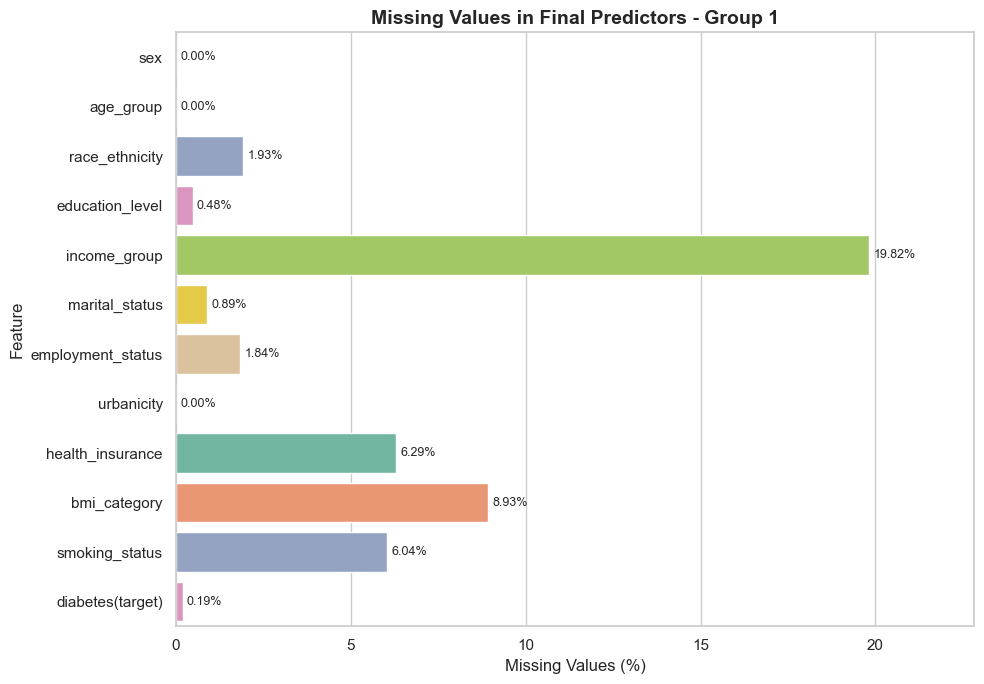

In [ ]:
plt.figure(figsize=(10, 7))
ax = sns.barplot( data=missing_plot1, y="Feature", x="Missing_%", hue="Feature", palette="Set2", legend=False )
plt.xlabel("Missing Values (%)")
plt.ylabel("Feature")
plt.title( "Missing Values in Final Predictors - Group 1", fontsize=14, fontweight="bold" )
# Add percentage labels
for container in ax.containers:
    ax.bar_label( container, fmt="%.2f%%", padding=3, fontsize=9 )
plt.xlim( 0, missing_summary["Missing_%"].max() + 3 )
plt.tight_layout()
plt.show()


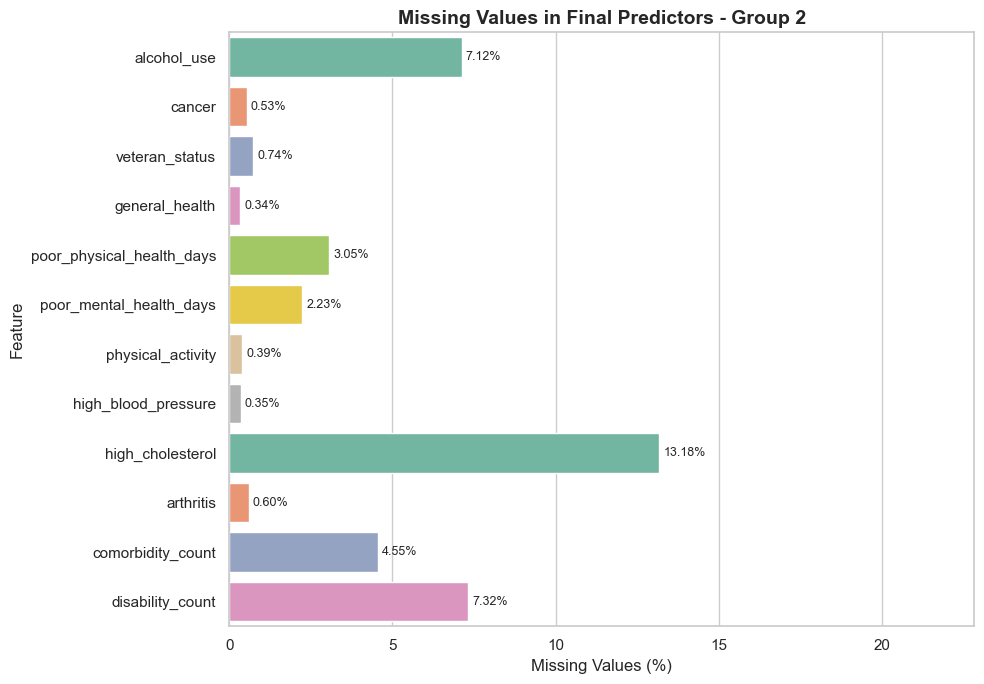

In [ ]:
plt.figure(figsize=(10, 7))
ax = sns.barplot( data=missing_plot2, y="Feature", x="Missing_%", hue="Feature", palette="Set2", legend=False )
plt.xlabel("Missing Values (%)")
plt.ylabel("Feature")
plt.title( "Missing Values in Final Predictors - Group 2", fontsize=14, fontweight="bold" )
# Add percentage labels
for container in ax.containers:
    ax.bar_label( container, fmt="%.2f%%", padding=3, fontsize=9 )
plt.xlim( 0, missing_summary["Missing_%"].max() + 3 )
plt.tight_layout()
plt.show()


In [ ]:
# Missingness plots above include all respondents, including missing targets.
# For subsequent analyses, require a valid target and retain missing predictors.
eda_data = eda_data.loc[eda_data["diabetes(target)"].notna()].copy()
print("EDA sample size with a valid diabetes target:", len(eda_data))


EDA sample size with a valid diabetes target: 5634


### 7.2 Outlier checks


In [ ]:
from IPython.display import display
# Match the target-valid EDA sample by the original respondent index.
bmi_source = pd.to_numeric(s1_data.loc[eda_data.index, "_BMI5"], errors="coerce") / 100
bmi_invalid = bmi_source.notna() & (~np.isfinite(bmi_source) | bmi_source.le(0))
bmi_numeric = bmi_source.mask(bmi_invalid)
bmi_observed = bmi_numeric.dropna()
q1, q3 = bmi_observed.quantile([0.25, 0.75])
iqr = q3 - q1
lower_fence, upper_fence = q1 - 1.5 * iqr, q3 + 1.5 * iqr
bmi_outlier_flag = bmi_numeric.lt(lower_fence) | bmi_numeric.gt(upper_fence)
outlier_summary = pd.DataFrame([{ "Variable": "BMI (kg/m?)",
    "Sample_n": len(eda_data), "Missing_n": int(bmi_source.isna().sum()), "Invalid_n": int(bmi_invalid.sum()), "Observed_n": len(bmi_observed),
    "Q1": q1, "Q3": q3, "IQR": iqr, "Lower_fence": lower_fence, "Upper_fence": upper_fence, "Flagged_n": int(bmi_outlier_flag.sum()),
    "Flagged_%_observed": 100 * bmi_outlier_flag.sum() / len(bmi_observed) if len(bmi_observed) else np.nan }])
display(outlier_summary.round(2))
bmi_outlier_review = eda_data.loc[bmi_outlier_flag, ["bmi_category", "diabetes(target)"]].copy()
bmi_outlier_review.insert(0, "BMI", bmi_numeric.loc[bmi_outlier_flag])
display(bmi_outlier_review.sort_values("BMI", ascending=False).head(20))


In [ ]:
if not bmi_observed.empty:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    sns.boxplot(x=bmi_observed, ax=axes[0], color="#496A81")
    axes[0].set(title="Numerical BMI: outlier review", xlabel="BMI (kg/m?)")
    sns.histplot(bmi_observed, bins=30, ax=axes[1], color="#496A81")
    for fence in (lower_fence, upper_fence):
        axes[1].axvline(fence, color="#B56A5A", linestyle="--")
    axes[1].set(title="BMI distribution and 1.5 ? IQR fences", xlabel="BMI (kg/m?)")
    plt.tight_layout()
    plt.show()
else:
    print("No valid numerical BMI observations; IQR outliers cannot be assessed.")
# Rare categorical levels: review flags, not numerical outliers.
rare_category_rows = []
for feature in final_23_features:
    counts = eda_data[feature].value_counts(dropna=True)
    observed_n = int(counts.sum())
    for level, count in counts.items():
        rare_category_rows.append({ "Feature": feature, "Category": level, "Count": int(count),
            "Percent_observed": 100 * count / observed_n, "Flag_review": count < 50 or count / observed_n < 0.01 })


In [ ]:
category_frequency_audit = pd.DataFrame(rare_category_rows)
rare_category_review = category_frequency_audit.loc[category_frequency_audit["Flag_review"]].copy()
display(rare_category_review.round(2))
print(f"BMI IQR review flags: {bmi_outlier_flag.sum():,}. Rare levels: {len(rare_category_review)}.")
print("Cleaning decision: retain flagged respondents and categories; investigate before any treatment.")


## 8. Feature distributions


In [ ]:
# Analyse each predictor using its available observations.
# Keep predictor missingness in eda_data for later MICE imputation.
for col in final_23_features:
    values = eda_data[col].dropna()
    counts = values.value_counts(sort=False)
    percentages = ( values.value_counts(normalize=True, sort=False) .mul(100) .round(2) )
    summary = pd.DataFrame({ "Count": counts, "Percentage": percentages })
    print("\n", col)
    display(summary)



 sex


,Count,Percentage
sex,,
Female,2927,51.95
Male,2707,48.05



 age_group


,Count,Percentage
age_group,,
45-54,913,16.21
65+,1865,33.10
55-64,1035,18.37
35-44,765,13.58
18-24,385,6.83
25-34,671,11.91



 race_ethnicity


...

,Count,Percentage
arthritis,,
No,3502,62.47
Yes,2104,37.53



 comorbidity_count


,Count,Percentage
comorbidity_count,,
0,2962,55.04
1-2,2117,39.33
3+,303,5.63



 disability_count


,Count,Percentage
disability_count,,
0,3313,63.41
3+,461,8.82
1-2,1451,27.77


In [ ]:
binary_features = [ "sex", "marital_status", "employment_status", "urbanicity", "health_insurance",
    "general_health", "cancer", "veteran_status", "physical_activity", "high_blood_pressure", "high_cholesterol", "arthritis", "alcohol_use" ]
# The remaining predictors have more than two defined categories.
other_features = [ feature for feature in final_23_features if feature not in binary_features ]
print("Binary features:", len(binary_features), binary_features)
print("Other features:", len(other_features), other_features)


Binary features: 13 ['sex', 'marital_status', 'employment_status', 'urbanicity', 'health_insurance', 'general_health', 'cancer', 'veteran_status', 'physical_activity', 'high_blood_pressure', 'high_cholesterol', 'arthritis', 'alcohol_use']
Other features: 10 ['age_group', 'race_ethnicity', 'education_level', 'income_group', 'bmi_category', 'smoking_status', 'poor_physical_health_days', 'poor_mental_health_days', 'comorbidity_count', 'disability_count']


### 8.1 Binary features


In [ ]:
# Binary feature distributions: one figure with multiple subplots.
ncols = 3
nrows = int(np.ceil(len(binary_features) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(18, 4.5 * nrows), squeeze=False)
for ax, feature in zip(axes.flat, binary_features):
    # Percentages are based on non-missing responses for this feature.
    values = eda_data[feature].dropna()
    if isinstance(values.dtype, pd.CategoricalDtype):
        values = values.cat.remove_unused_categories()
    counts = values.value_counts(sort=False)
    counts = counts[counts > 0]
    title = feature.replace("_", " ").title()
    ax.set_title(title, fontsize=12, fontweight="bold", pad=12)
    if counts.empty:
        ax.text(0.5, 0.5, "No non-missing responses", ha="center", va="center", transform=ax.transAxes)
        ax.set_axis_off()
        continue
    bars = ax.bar( np.arange(len(counts)), counts.to_numpy(), color=sns.color_palette("Set2", n_colors=len(counts)), edgecolor="#2F2F2F" )
    labels = [ f"{count:,}\n({count / counts.sum() * 100:.1f}%)" for count in counts ]
    ax.bar_label(bars, labels=labels, padding=3, fontsize=8)
    ax.set_xticks(np.arange(len(counts)))
    ax.set_xticklabels(counts.index.astype(str), rotation=30, ha="right", fontsize=9)
    ax.set_xlabel("")
    ax.set_ylabel("Count")
    ax.set_ylim(0, counts.max() * 1.25)
    ax.grid(axis="y", alpha=0.2)
    ax.set_axisbelow(True)


In [ ]:
for ax in list(axes.flat)[len(binary_features):]:
    ax.set_visible(False)
fig.suptitle("Binary Feature Distributions", fontsize=18, fontweight="bold")
fig.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()


### 8.2 Other features


In [ ]:
# Other feature distributions: one figure with multiple subplots.
ncols = 3
nrows = int(np.ceil(len(other_features) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(18, 4.5 * nrows), squeeze=False)
for ax, feature in zip(axes.flat, other_features):
    # Percentages are based on non-missing responses for this feature.
    values = eda_data[feature].dropna()
    if isinstance(values.dtype, pd.CategoricalDtype):
        values = values.cat.remove_unused_categories()
    counts = values.value_counts(sort=False)
    counts = counts[counts > 0]
    title = feature.replace("_", " ").title()
    ax.set_title(title, fontsize=12, fontweight="bold", pad=12)
    if counts.empty:
        ax.text(0.5, 0.5, "No non-missing responses", ha="center", va="center", transform=ax.transAxes)
        ax.set_axis_off()
        continue
    bars = ax.bar( np.arange(len(counts)), counts.to_numpy(), color=sns.color_palette("Set2", n_colors=len(counts)), edgecolor="#2F2F2F" )
    labels = [ f"{count:,}\n({count / counts.sum() * 100:.1f}%)" for count in counts ]
    ax.bar_label(bars, labels=labels, padding=3, fontsize=8)
    ax.set_xticks(np.arange(len(counts)))
    ax.set_xticklabels(counts.index.astype(str), rotation=30, ha="right", fontsize=9)
    ax.set_xlabel("")
    ax.set_ylabel("Count")
    ax.set_ylim(0, counts.max() * 1.25)
    ax.grid(axis="y", alpha=0.2)
    ax.set_axisbelow(True)


In [ ]:
for ax in list(axes.flat)[len(other_features):]:
    ax.set_visible(False)
fig.suptitle("Other Feature Distributions", fontsize=18, fontweight="bold")
fig.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()


In [ ]:
binary_summary = []
for col in binary_features:
    counts = eda_data[col].value_counts(dropna=True)
    percentages = ( eda_data[col] .value_counts(normalize=True, dropna=True) .mul(100) .round(2) )
    for category in counts.index:
        binary_summary.append({ "Feature": col, "Category": category, "Count": counts.loc[category], "Percentage": percentages.loc[category] })
binary_summary = pd.DataFrame(binary_summary)
binary_summary


,Feature,Category,Count,Percentage
0,sex,Female,2927,51.95
1,sex,Male,2707,48.05
2,marital_status,Unmarried,2796,50.04
3,marital_status,Married,2791,49.96
4,employment_status,Employed,2798,50.56
5,employment_status,Unemployed,2736,49.44
6,urbanicity,Urban,4963,88.09
7,urbanicity,Rural,671,11.91
8,health_insurance,Insured,4867,92.13
9,health_insurance,Not insured,416,7.87


## 9. Relationships with diabetes


In [ ]:
def diabetes_table(data, feature):
    # Percentages use respondents with both feature and target available.
    valid_data = data[[feature, "diabetes(target)"]].dropna()
    table = pd.crosstab( valid_data[feature], valid_data["diabetes(target)"], normalize="index" ).mul(100).reindex(columns=[0, 1], fill_value=0)
    return table.rename(columns={ 0: "No Diabetes %", 1: "Diabetes %" }).round(2)


In [ ]:
diabetes_table(eda_data, "age_group")


diabetes(target),No Diabetes %,Diabetes %
age_group,,
18-24,96.62,3.38
25-34,94.04,5.96
35-44,91.24,8.76
45-54,84.12,15.88
55-64,75.75,24.25
65+,72.60,27.40


In [ ]:
diabetes_table(eda_data, "bmi_category")


diabetes(target),No Diabetes %,Diabetes %
bmi_category,,
Normal,90.46,9.54
Obese,72.56,27.44
Overweight,84.14,15.86
Underweight,94.67,5.33


In [ ]:
diabetes_table(eda_data,"high_blood_pressure")


diabetes(target),No Diabetes %,Diabetes %
high_blood_pressure,,
No,92.23,7.77
Yes,69.39,30.61


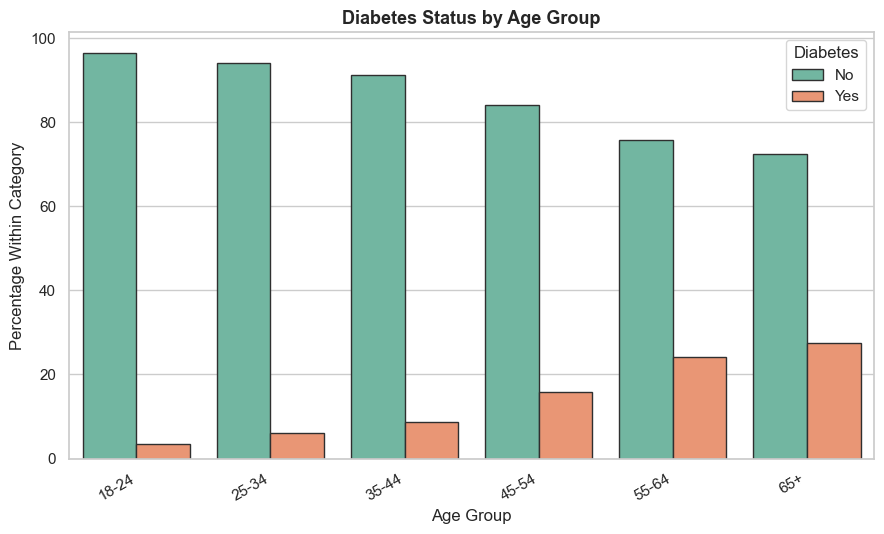

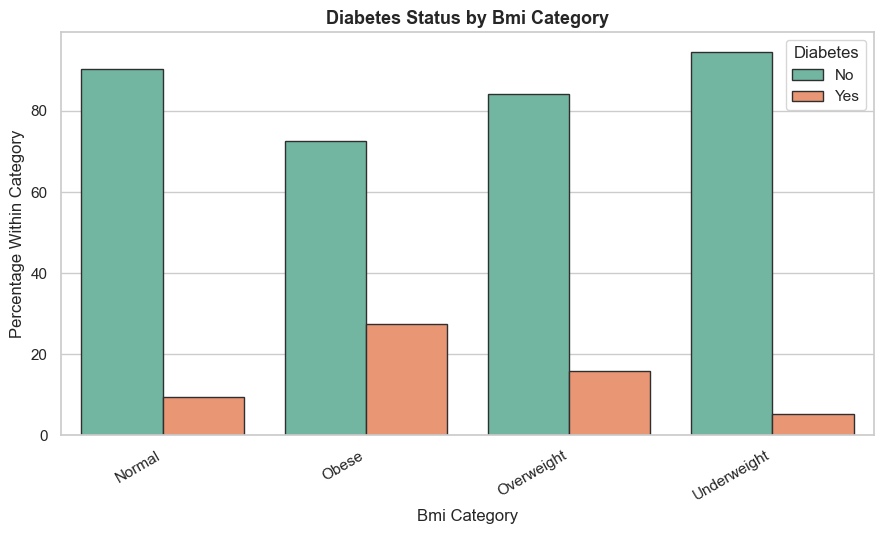

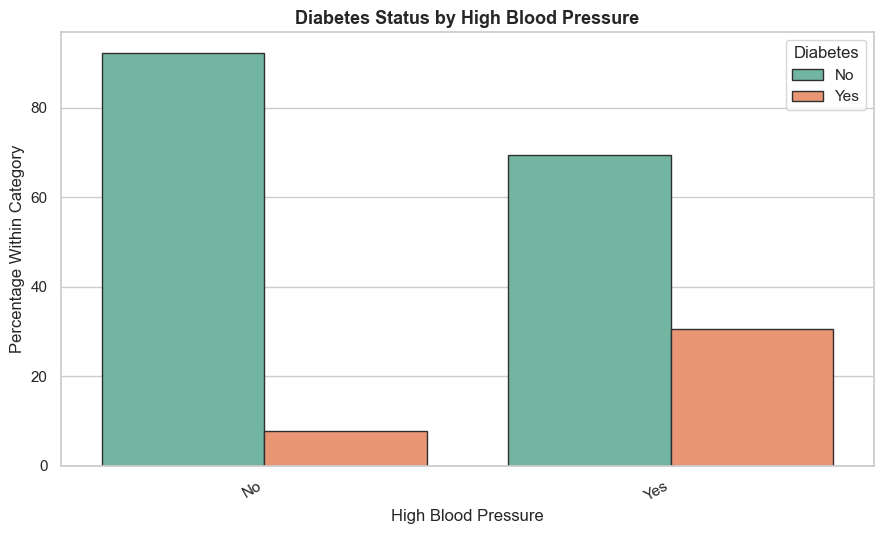

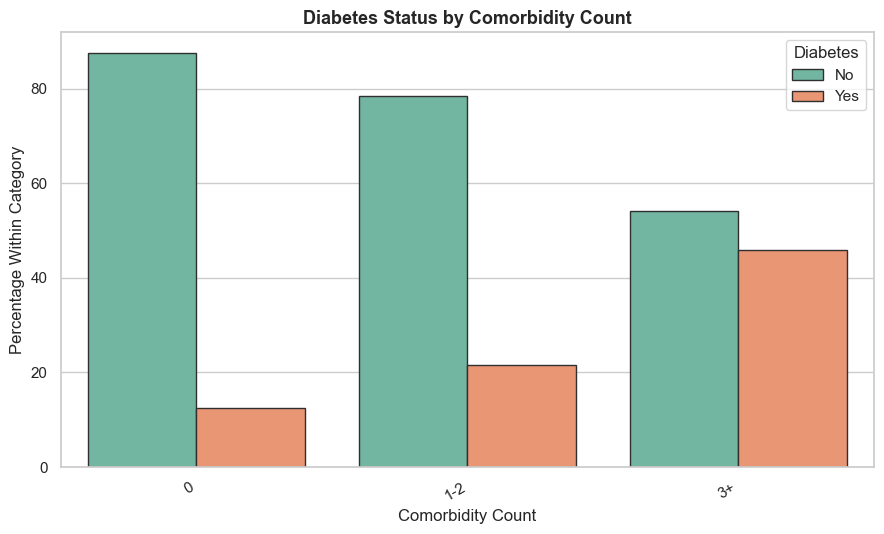

In [ ]:
diabetes_relationship_features = ['age_group', 'bmi_category', 'high_blood_pressure', 'comorbidity_count']
for feature in diabetes_relationship_features:
    valid_data = eda_data[[feature, "diabetes(target)"]].dropna()
    if valid_data.empty:
        print(f"No complete responses for {feature} and diabetes; skipping plot.")
        continue
    plot_data = pd.crosstab(
        valid_data[feature], valid_data["diabetes(target)"], normalize="index" ).mul(100).reindex(columns=[0, 1], fill_value=0).reset_index()
    plot_data = plot_data.melt( id_vars=feature, var_name="Diabetes", value_name="Percentage" )
    plot_data["Diabetes"] = plot_data["Diabetes"].map({ 0: "No", 1: "Yes" })
    plt.figure(figsize=(9, 5.5))
    sns.barplot( data=plot_data, x=feature, y="Percentage", hue="Diabetes", palette="Set2", edgecolor="#2F2F2F" )
    plt.xlabel( feature.replace("_", " ").title() )
    plt.ylabel("Percentage Within Category")
    plt.title( f"Diabetes Status by {feature.replace('_', ' ').title()}", fontsize=13, fontweight="bold" )
    plt.xticks(rotation=30, ha="right")
    plt.tight_layout()
    plt.show()


## 10. Statistical analysis

### 10.1 Chi-square tests


In [ ]:
from scipy.stats import chi2_contingency
chi_results = []
for col in final_23_features:
    temp = eda_data[ [col, "diabetes(target)"] ].dropna()
    table = pd.crosstab( temp[col], temp["diabetes(target)"] )
    # Remove unused categories before testing.
    table = table.loc[table.sum(axis=1) > 0, table.sum(axis=0) > 0]
    if min(table.shape) < 2:
        chi2, p, dof = np.nan, np.nan, 0
    else:
        chi2, p, dof, expected = chi2_contingency(table, correction=False)
    chi_results.append({ "Feature": col, "Chi2": round(chi2, 3), "df": dof, "p_value": p })
chi_results = pd.DataFrame( chi_results ).sort_values("p_value")
chi_results


,Feature,Chi2,df,p_value
18,high_blood_pressure,488.195,1,3.520855e-108
14,general_health,334.058,1,1.255654e-74
19,high_cholesterol,291.914,1,1.902948e-65
1,age_group,304.538,5,1.058932e-63
21,comorbidity_count,240.650,2,5.539690e-53
20,arthritis,190.763,1,2.166392e-43
9,bmi_category,194.015,3,8.282376e-42
22,disability_count,187.535,2,1.893757e-41
6,employment_status,164.127,1,1.418773e-37
15,poor_physical_health_days,164.984,2,1.493186e-36


### 10.2 Cram?r's V


In [ ]:
def cramers_v(x, y):
    valid_data = pd.concat([x.rename("x"), y.rename("y")], axis=1).dropna()
    table = pd.crosstab(valid_data["x"], valid_data["y"])
    table = table.loc[table.sum(axis=1) > 0, table.sum(axis=0) > 0]
    if min(table.shape) < 2:
        return np.nan
    chi2 = chi2_contingency(table, correction=False)[0]
    n = table.to_numpy().sum()
    denominator = min(table.shape[0] - 1, table.shape[1] - 1)
    return np.sqrt(chi2 / (n * denominator))


In [ ]:
association_results = []
for col in final_23_features:
    temp = eda_data[ [col, "diabetes(target)"] ].dropna()
    table = pd.crosstab( temp[col], temp["diabetes(target)"] )
    # Remove unused categories before testing.
    table = table.loc[table.sum(axis=1) > 0, table.sum(axis=0) > 0]
    if min(table.shape) < 2:
        chi2, p, dof = np.nan, np.nan, 0
    else:
        chi2, p, dof, expected = chi2_contingency(table, correction=False)
    v = cramers_v( temp[col], temp["diabetes(target)"] )
    association_results.append({ "Feature": col, "Chi2": round(chi2, 3), "p_value": p, "Cramers_V": round(v, 3) })
association_results = pd.DataFrame( association_results ).sort_values( "Cramers_V", ascending=False )
association_results


,Feature,Chi2,p_value,Cramers_V
18,high_blood_pressure,488.195,3.520855e-108,0.295
14,general_health,334.058,1.255654e-74,0.244
19,high_cholesterol,291.914,1.902948e-65,0.244
1,age_group,304.538,1.058932e-63,0.232
21,comorbidity_count,240.650,5.539690e-53,0.211
9,bmi_category,194.015,8.282376e-42,0.194
22,disability_count,187.535,1.893757e-41,0.189
20,arthritis,190.763,2.166392e-43,0.184
15,poor_physical_health_days,164.984,1.493186e-36,0.174
6,employment_status,164.127,1.418773e-37,0.172


### 10.3 Association between predictors


In [ ]:
def cramers_v_matrix(data):
    columns = data.columns
    matrix = pd.DataFrame(np.nan, index=columns, columns=columns)
    for i, col1 in enumerate(columns):
        for col2 in columns[i:]:
            # Pass Series directly so diagonal entries do not duplicate columns.
            value = cramers_v(data[col1], data[col2])
            matrix.loc[col1, col2] = value
            matrix.loc[col2, col1] = value
    return matrix


In [ ]:
cramers_matrix = cramers_v_matrix(eda_data[final_23_features])
cramers_matrix.round(2)


,sex,age_group,race_ethnicity,education_level,income_group,marital_status,employment_status,urbanicity,health_insurance,bmi_category,...,veteran_status,general_health,poor_physical_health_days,poor_mental_health_days,physical_activity,high_blood_pressure,high_cholesterol,arthritis,comorbidity_count,disability_count
sex,1.00,0.05,0.08,0.04,0.14,0.07,0.14,0.00,0.05,0.12,...,0.31,0.01,0.09,0.14,0.07,0.05,0.02,0.10,0.12,0.06
age_group,0.05,1.00,0.12,0.10,0.13,0.25,0.54,0.06,0.20,0.08,...,0.18,0.18,0.12,0.21,0.17,0.39,0.29,0.38,0.11,0.14
race_ethnicity,0.08,0.12,1.00,0.05,0.07,0.15,0.07,0.10,0.13,0.06,...,0.03,0.05,0.06,0.06,0.04,0.10,0.05,0.10,0.05,0.06
education_level,0.04,0.10,0.05,1.00,0.28,0.23,0.22,0.13,0.14,0.05,...,0.08,0.26,0.13,0.10,0.24,0.13,0.08,0.14,0.14,0.20
income_group,0.14,0.13,0.07,0.28,1.00,0.44,0.44,0.10,0.15,0.07,...,0.08,0.36,0.22,0.14,0.28,0.16,0.13,0.20,0.23,0.29
marital_status,0.07,0.25,0.15,0.23,0.44,1.00,0.09,0.00,0.12,0.10,...,0.08,0.12,0.11,0.17,0.11,0.00,0.01,0.00,0.13,0.17
employment_status,0.14,0.54,0.07,0.22,0.44,0.09,1.00,0.05,0.04,0.07,...,0.09,0.28,0.26,0.12,0.19,0.23,0.19,0.30,0.25,0.35
urbanicity,0.00,0.06,0.10,0.13,0.10,0.00,0.05,1.00,0.02,0.02,...,0.03,0.07,0.06,0.05,0.06,0.04,0.04,0.05,0.01,0.06
health_insurance,0.05,0.20,0.13,0.14,0.15,0.12,0.04,0.02,1.00,0.04,...,0.08,0.04,0.05,0.11,0.00,0.07,0.07,0.08,0.02,0.04
bmi_category,0.12,0.08,0.06,0.05,0.07,0.10,0.07,0.02,0.04,1.00,...,0.05,0.13,0.09,0.08,0.12,0.20,0.10,0.14,0.08,0.08


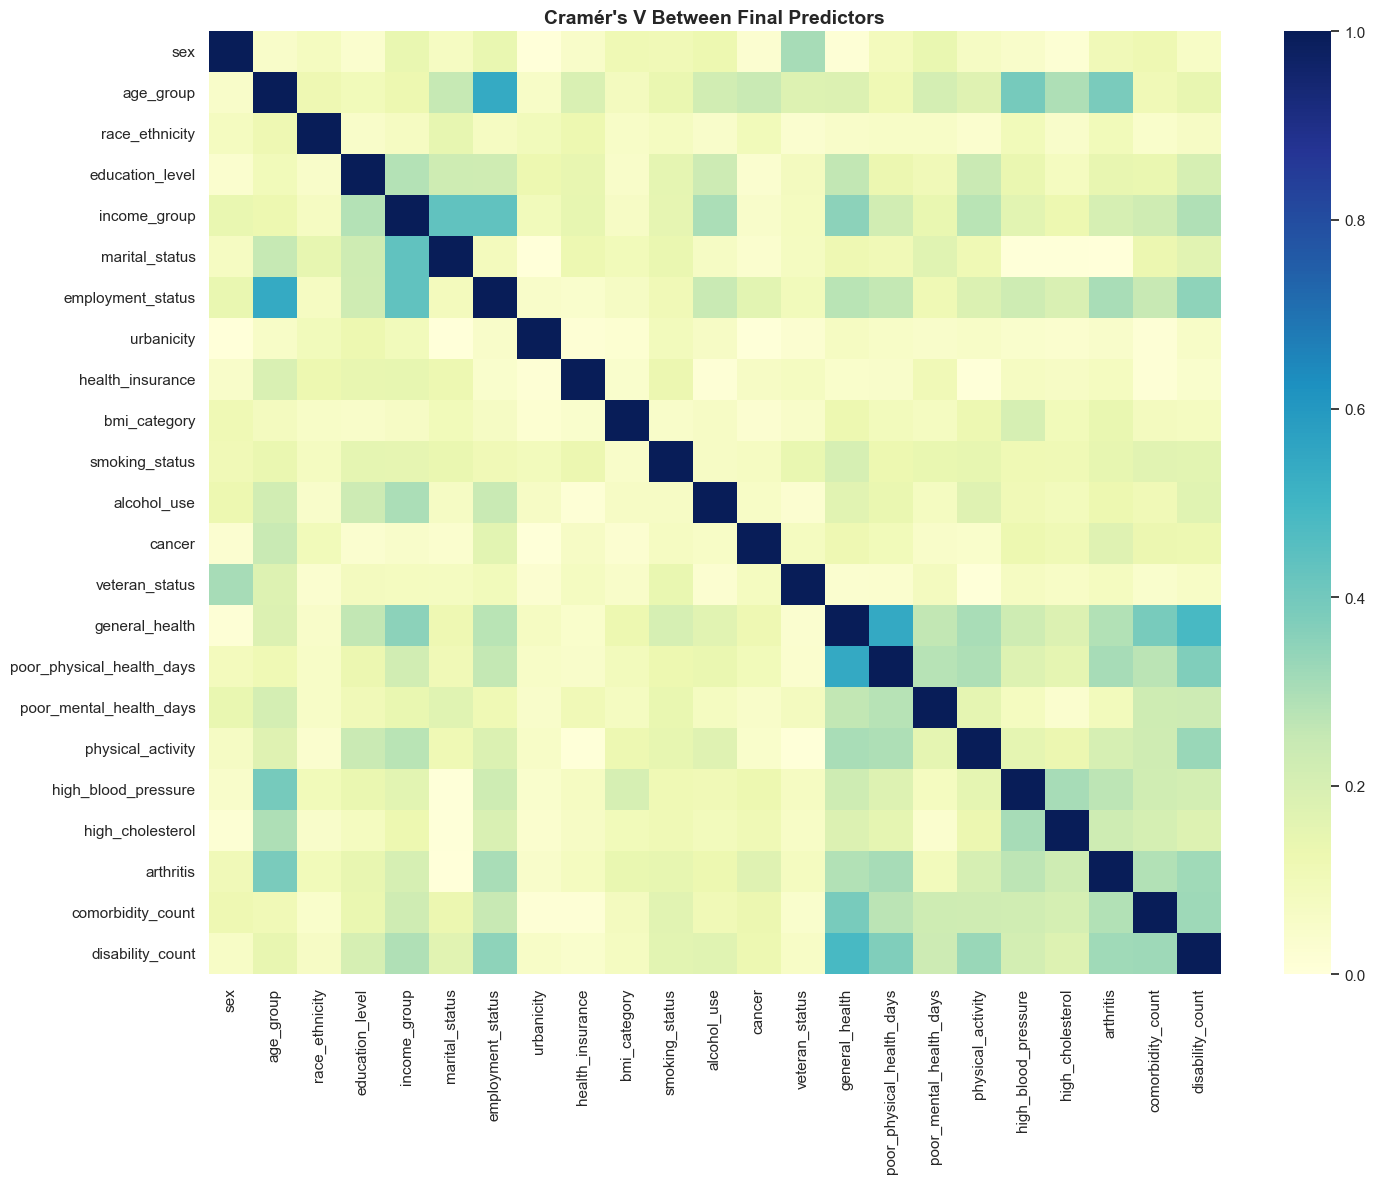

In [ ]:
plt.figure(figsize=(15, 12))
sns.heatmap( cramers_matrix, cmap="YlGnBu", vmin=0, vmax=1 )
plt.title( "Cramér's V Between Final Predictors", fontsize=14, fontweight="bold" )
plt.tight_layout()
plt.show()


In [ ]:
strong_pairs = []
for i in range(len(cramers_matrix.columns)):
    for j in range(i + 1, len(cramers_matrix.columns)):
        strong_pairs.append({
            "Feature_1": cramers_matrix.columns[i], "Feature_2": cramers_matrix.columns[j], "Cramers_V": cramers_matrix.iloc[i, j] })
strong_pairs = pd.DataFrame( strong_pairs ).sort_values( "Cramers_V", ascending=False )
strong_pairs.head(15)


,Feature_1,Feature_2,Cramers_V
217,general_health,poor_physical_health_days,0.543462
26,age_group,employment_status,0.541905
224,general_health,disability_count,0.484918
83,income_group,employment_status,0.436712
82,income_group,marital_status,0.436516
38,age_group,high_blood_pressure,0.391388
223,general_health,comorbidity_count,0.390599
40,age_group,arthritis,0.383663
231,poor_physical_health_days,disability_count,0.373335
91,income_group,general_health,0.355404
